# FairGRUNT-T: fairness-aware temporal fraud detection on DGraphFin

This notebook contains **all of the project's code** in one place, in the order it runs:

| Section | Source file | What it does |
|---|---|---|
| 1 | `config.py` | Every hyper-parameter and the three experiment settings |
| 2 | `metrics.py` | Statistical-parity / equal-opportunity gaps, AUC, F1 threshold search |
| 3 | `model.py` | Residual GCN + MLP encoder + fraud and cohort heads |
| 4 | `data_loader.py` | Fraud-seeded BFS subgraph, temporal adjacency, features, split, cohorts |
| 5 | `train.py` | Training loop (Algorithm 1) |
| 6 | `run_experiments.py` | Runs the three (α, β) settings and saves the results |
| 7 | `report.py` | Prints the results tables (Tables IV and V) |
| 8 | `make_figures.py` | Draws each figure, **one figure per cell, shown inline** |

**To run:** put `dgraphfin.npz` in `data/DGraphFin/`, open this notebook from the project
folder and choose *Run All*. Each figure cell shows its image below the cell and also saves it
to `figures/` as PNG (300 dpi) and PDF.

## 0. Setup

In [1]:
# Requirements (tested with Python 3.13, CPU only):
#   pip install torch numpy scipy scikit-learn matplotlib
import gc
import json
import math
import os
import time
from collections import deque
from dataclasses import dataclass, field, replace

import numpy as np
import scipy.sparse as sp
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, roc_auc_score

import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
%matplotlib inline

print("torch", torch.__version__, "| numpy", np.__version__, "| working dir:", os.getcwd())

torch 2.14.1+cu126 | numpy 2.4.6 | working dir: C:\Users\khais\Desktop\FairGrunt\FairGRUNT


## 1. Configuration  (`config.py`)

All settings used in the paper, kept in one place.

Change values here (or override alpha/beta/epochs from the command line in
run_experiments.py). The defaults reproduce the reported results.

In [2]:
@dataclass
class DataConfig:
    path: str = "data/DGraphFin/dgraphfin.npz"
    seed: int = 42                  # NumPy seed: fraud seeds for BFS and the random split
    n_fraud_seeds: int = 500        # BFS starts from this many random fraud nodes
    max_visited: int = 50_000       # BFS stops expanding after visiting this many nodes
    max_extra_edges: int = 500_000  # safety cap for the second edge scan (never reached)
    train_frac: float = 0.6         # random 60/20/20 split, not stratified
    val_frac: float = 0.2


@dataclass
class ModelConfig:
    gcn_hidden: int = 128           # residual GCN: d -> 128 -> 128 -> 64
    emb_dim: int = 64               # size of the embedding h_v
    cohort_dim: int = 16            # z_s, first 16 dims of h_v (cohort subspace)
    mlp_hidden: int = 128           # MLP encoder: 64 -> 128 -> 64
    task_head: tuple = (64, 32)     # fraud predictor: 48 -> 64 -> 32 -> 2
    cohort_head: tuple = (32, 16)   # cohort predictor: 16 -> 32 -> 16 -> 2
    gcn_dropout: float = 0.3
    mlp_dropout: float = 0.2


@dataclass
class TrainConfig:
    alpha: float = 0.0              # weight of the decorrelation loss L_dis
    beta: float = 0.0               # weight of the soft statistical-parity penalty
    epochs: int = 500
    lr: float = 1e-3
    weight_decay: float = 5e-4
    seed: int = 42                  # torch seed: weight init and dropout
    max_fraud_weight: float = 15.0  # w1 = min(N0/N1, 15) in the weighted cross-entropy
    grad_clip: float = 1.0
    eval_every: int = 10            # validation check (checkpoint, scheduler, early stop)
    patience: int = 80              # early stopping, counted in epochs
    lr_factor: float = 0.5          # ReduceLROnPlateau settings
    lr_patience: int = 30           # counted in validation checks, not epochs
    min_lr: float = 1e-5
    thresholds: tuple = (0.10, 0.90, 0.02)  # validation-F1 threshold grid: start, stop, step


@dataclass
class Config:
    data: DataConfig = field(default_factory=DataConfig)
    model: ModelConfig = field(default_factory=ModelConfig)
    train: TrainConfig = field(default_factory=TrainConfig)


# The three settings compared in the paper.
EXPERIMENTS = [
    {"name": "Temporal backbone", "alpha": 0.0, "beta": 0.0},
    {"name": "Moderate", "alpha": 0.01, "beta": 1.0},
    {"name": "Strong", "alpha": 0.05, "beta": 5.0},
]

## 2. Metrics  (`metrics.py`)

Group-disparity metrics and the validation-F1 threshold search.

In [3]:
def fairness_gaps(pred, labels, group):
    """Statistical-parity and equal-opportunity gaps between groups 0 and 1.

    SP = |P(y_hat=1 | s=0) - P(y_hat=1 | s=1)|
    EO = |P(y_hat=1 | y=1, s=0) - P(y_hat=1 | y=1, s=1)|
    """
    g0, g1 = group == 0, group == 1
    sp = abs(pred[g0].mean() - pred[g1].mean())
    tpr0 = ((pred[g0] == 1) & (labels[g0] == 1)).sum() / max(labels[g0].sum(), 1)
    tpr1 = ((pred[g1] == 1) & (labels[g1] == 1)).sum() / max(labels[g1].sum(), 1)
    return float(sp), float(abs(tpr0 - tpr1))


def safe_auc(labels, scores):
    try:
        return roc_auc_score(labels, scores)
    except ValueError:  # only one class present
        return 0.5


def best_f1_threshold(labels, scores, grid):
    """Threshold on `grid` (start, stop, step) with the highest F1; first one wins ties."""
    best_f1, best_t = 0.0, 0.5
    for t in np.arange(*grid):
        f1 = f1_score(labels, (scores >= t).astype(int), zero_division=0)
        if f1 > best_f1:
            best_f1, best_t = f1, t
    return best_t

## 3. Model  (`model.py`)

FairGRUNT-T network: residual GCN encoder, MLP encoder and two prediction heads.

In [4]:
class GraphConvolution(nn.Module):
    """GCN layer (Kipf & Welling, 2017): A_hat @ X @ W + b."""

    def __init__(self, in_features, out_features):
        super().__init__()
        self.weight = nn.Parameter(torch.empty(in_features, out_features))
        self.bias = nn.Parameter(torch.empty(out_features))
        nn.init.xavier_normal_(self.weight)
        bound = 1.0 / math.sqrt(out_features)
        nn.init.uniform_(self.bias, -bound, bound)

    def forward(self, x, adj):
        return torch.spmm(adj, x @ self.weight) + self.bias


class ResidualGCN(nn.Module):
    """Three GCN layers with BatchNorm and a residual link around the second layer."""

    def __init__(self, n_in, n_hidden, n_out, dropout):
        super().__init__()
        self.gc1, self.bn1 = GraphConvolution(n_in, n_hidden), nn.BatchNorm1d(n_hidden)
        self.gc2, self.bn2 = GraphConvolution(n_hidden, n_hidden), nn.BatchNorm1d(n_hidden)
        self.gc3, self.bn3 = GraphConvolution(n_hidden, n_out), nn.BatchNorm1d(n_out)
        self.dropout = dropout

    def forward(self, x, adj):
        x = F.dropout(F.relu(self.bn1(self.gc1(x, adj))), self.dropout, self.training)
        x = F.dropout(F.relu(self.bn2(self.gc2(x, adj))), self.dropout, self.training) + x
        return self.bn3(self.gc3(x, adj))


def mlp(sizes, dropout):
    """Linear layers with ReLU and dropout between them (none after the last layer)."""
    layers = []
    for i in range(len(sizes) - 2):
        layers += [nn.Linear(sizes[i], sizes[i + 1]), nn.ReLU(), nn.Dropout(dropout)]
    layers.append(nn.Linear(sizes[-2], sizes[-1]))
    return nn.Sequential(*layers)


class FairGRUNTT(nn.Module):
    """h_v = MLP(GCN(X, A_hat)) is split into z_s (cohort) and z_c (task).

    The fraud head sees only z_c and the cohort head sees only z_s.
    """

    def __init__(self, n_features, cfg):
        super().__init__()
        self.cohort_dim = cfg.cohort_dim
        task_dim = cfg.emb_dim - cfg.cohort_dim
        # Construction order matters for reproducing the reported runs (same RNG draws).
        self.gcn = ResidualGCN(n_features, cfg.gcn_hidden, cfg.emb_dim, cfg.gcn_dropout)
        self.encoder = mlp([cfg.emb_dim, cfg.mlp_hidden, cfg.emb_dim], cfg.mlp_dropout)
        self.task_head = mlp([task_dim, *cfg.task_head, 2], cfg.mlp_dropout)
        self.cohort_head = mlp([cfg.cohort_dim, *cfg.cohort_head, 2], cfg.mlp_dropout)

    def embed(self, x, adj):
        h = self.encoder(self.gcn(x, adj))
        return h[:, :self.cohort_dim], h[:, self.cohort_dim:], h  # z_s, z_c, h

    @torch.no_grad()
    def fraud_probability(self, x, adj):
        _, z_c, _ = self.embed(x, adj)
        return F.softmax(self.task_head(z_c), dim=1)[:, 1]

## 4. Data loading  (`data_loader.py`)

Load DGraphFin, take a fraud-seeded subgraph and build the model inputs.

Steps (Section V-A of the paper):
  1. BFS from 500 random fraud nodes over the full graph (incl. background nodes)
     until 50,000 nodes have been visited.
  2. Keep only labelled nodes (class 0 = normal, 1 = fraud) and the edges between them.
  3. Build a fixed recency-weighted adjacency  a_e = 0.5 + 0.5 * t_e / t_max,
     symmetrise with max(A, A^T), add self-loops and normalise.
  4. Min-max scale the 17 node features.
  5. Random 60/20/20 split.
  6. Build the binary early/late temporal cohort used as the group attribute.

In [5]:
def _neighbour_lists(edge_index, n_nodes):
    """CSR-style neighbour lists over the undirected view of the graph.

    For every node the neighbours are listed in edge order, so the BFS visits
    nodes in exactly the same order as a plain dict-of-lists implementation.
    """
    src, dst = edge_index[:, 0], edge_index[:, 1]
    edge_ids = np.arange(len(src))
    node = np.concatenate([src, dst])
    neighbour = np.concatenate([dst, src])
    eid = np.concatenate([edge_ids, edge_ids])
    side = np.repeat([0, 1], len(src))
    order = np.lexsort((side, eid, node))
    indptr = np.concatenate([[0], np.cumsum(np.bincount(node, minlength=n_nodes))])
    return indptr, neighbour[order], eid[order]


def _bfs_sample(y, edge_index, cfg):
    """Fraud-seeded BFS. Returns visited node ids and the edge ids touched."""
    fraud = np.where(y == 1)[0]
    seeds = np.random.choice(fraud, size=min(cfg.n_fraud_seeds, len(fraud)), replace=False)
    indptr, neighbours, edge_ids = _neighbour_lists(edge_index, len(y))

    visited = set(seeds.tolist())
    queue = deque(seeds.tolist())
    touched_edges = set()
    while len(visited) < cfg.max_visited and queue:
        u = queue.popleft()
        for v, e in zip(neighbours[indptr[u]:indptr[u + 1]].tolist(),
                        edge_ids[indptr[u]:indptr[u + 1]].tolist()):
            touched_edges.add(e)
            if v not in visited and len(visited) < cfg.max_visited:
                visited.add(v)
                queue.append(v)

    # If the BFS runs out of nodes early, top up with random labelled nodes.
    if len(visited) < cfg.max_visited:
        labelled = np.where((y == 0) | (y == 1))[0]
        pool = np.setdiff1d(labelled, list(visited))
        extra = np.random.choice(pool, size=min(cfg.max_visited - len(visited), len(pool)), replace=False)
        visited.update(extra.tolist())
    return visited, touched_edges


def _normalised_adjacency(edges, weights, n):
    adj = sp.coo_matrix((weights, (edges[:, 0], edges[:, 1])), shape=(n, n), dtype=np.float32)
    # Symmetrise: A_uv = max(B_uv, B_vu)
    adj = adj + adj.T.multiply(adj.T > adj) - adj.multiply(adj.T > adj)
    with_self = sp.coo_matrix(adj + sp.eye(n))
    deg = np.array(with_self.sum(1)).flatten()
    d_inv_sqrt = np.power(deg, -0.5)
    d_inv_sqrt[np.isinf(d_inv_sqrt)] = 0.0
    d = sp.diags(d_inv_sqrt)
    norm = d.dot(with_self).dot(d).tocoo()
    indices = torch.from_numpy(np.vstack((norm.row, norm.col)).astype(np.int64))
    values = torch.from_numpy(norm.data.astype(np.float32))
    return adj, torch.sparse_coo_tensor(indices, values, torch.Size([n, n]), check_invariants=True)


def _temporal_cohort(edges, timestamps, adj, n):
    """Early (0) / late (1) cohort: sum of incident timestamps divided by the
    weighted degree, split at the median of the positive values."""
    score = np.zeros(n, dtype=np.float32)
    for (s, d), t in zip(edges, timestamps):
        score[s] += t
        score[d] += t
    degree = np.array(adj.sum(axis=1)).flatten()
    degree[degree == 0] = 1
    score /= degree
    median = np.median(score[score > 0]) if np.any(score > 0) else 0
    return (score > median).astype(np.int64)


def load_dgraphfin(cfg):
    t0 = time.time()
    print(f"Loading {cfg.path} ...")
    raw = np.load(cfg.path)
    x, y = raw["x"].astype(np.float32), raw["y"]
    edge_index, edge_type, edge_time = raw["edge_index"], raw["edge_type"], raw["edge_timestamp"]

    np.random.seed(cfg.seed)
    visited, touched_edges = _bfs_sample(y, edge_index, cfg)

    # Keep labelled nodes only (background classes 2 and 3 are dropped).
    nodes = np.sort(list(visited))
    nodes = nodes[np.isin(y[nodes], [0, 1])][:cfg.max_visited]
    n = len(nodes)
    new_id = np.full(len(y), -1, dtype=np.int64)
    new_id[nodes] = np.arange(n)

    # Edges with both endpoints kept: first those met during BFS, then any others.
    kept = lambda ids: ids[(new_id[edge_index[ids, 0]] >= 0) & (new_id[edge_index[ids, 1]] >= 0)]
    bfs_ids = kept(np.fromiter(touched_edges, dtype=np.int64, count=len(touched_edges)))
    in_bfs = np.zeros(len(edge_index), dtype=bool)
    in_bfs[list(touched_edges)] = True
    other_ids = kept(np.where(~in_bfs)[0])[:max(0, cfg.max_extra_edges - len(bfs_ids))]
    eids = np.concatenate([bfs_ids, other_ids])

    edges = new_id[edge_index[eids]]
    etype, etime = edge_type[eids], edge_time[eids]

    weights = 0.5 + 0.5 * etime.astype(np.float32) / etime.max()
    adj_raw, adj = _normalised_adjacency(edges, weights, n)

    feats = torch.FloatTensor(x[nodes])
    fmin, fmax = feats.min(dim=0)[0], feats.max(dim=0)[0]
    span = fmax - fmin
    span[span == 0] = 1.0
    feats = (feats - fmin) / span
    labels = torch.LongTensor(y[nodes])

    perm = np.random.permutation(n)
    n_train, n_val = int(cfg.train_frac * n), int(cfg.val_frac * n)
    masks = []
    for part in (perm[:n_train], perm[n_train:n_train + n_val], perm[n_train + n_val:]):
        m = torch.zeros(n, dtype=torch.bool)
        m[part] = True
        masks.append(m)

    cohort = torch.LongTensor(_temporal_cohort(edges, etime, adj_raw, n))

    hist, bins = np.histogram(etime, bins=20)
    types, type_counts = np.unique(etype, return_counts=True)
    stats = {
        "n_nodes": int(n), "n_edges": int(len(edges)),
        "n_fraud": int((labels == 1).sum()), "n_normal": int((labels == 0).sum()),
        "timestamp_range": [int(etime.min()), int(etime.max())],
        "n_edge_types": int(len(types)),
        "edge_type_dist": {int(k): int(v) for k, v in zip(types, type_counts)},
        "timestamp_dist": hist.tolist(), "timestamp_bins": bins.tolist(),
    }
    print(f"  {n:,} labelled nodes, {len(edges):,} edges, {stats['n_fraud']:,} fraud "
          f"| split {int(masks[0].sum())}/{int(masks[1].sum())}/{int(masks[2].sum())} "
          f"| cohorts {int((cohort == 0).sum())}/{int((cohort == 1).sum())} | {time.time() - t0:.0f}s")
    return {"adj": adj, "features": feats, "labels": labels, "cohort": cohort,
            "train": masks[0], "val": masks[1], "test": masks[2], "stats": stats}

## 5. Training loop  (`train.py`)

Training loop for one (alpha, beta) setting of FairGRUNT-T.

Each epoch has three updates (Algorithm 1 in the paper):
  1. fraud head on detached z_c (weighted cross-entropy, training nodes)
  2. cohort head on detached z_s (cross-entropy, training nodes)
  3. GCN + MLP encoder on
       L = (1 - alpha) * (L_cls + L_sens) + alpha * L_dis + beta * SP_soft
     where L_dis is the largest |Pearson correlation| between a z_s and a z_c
     coordinate (training nodes) and SP_soft is the gap in mean fraud score
     between the two cohorts (computed over all nodes, i.e. transductively).

Every `eval_every` epochs the validation AUC drives checkpointing, the LR
schedulers and early stopping. Test metrics are only logged for monitoring.

In [6]:
def _adam(params, cfg):
    return torch.optim.Adam(params, lr=cfg.lr, weight_decay=cfg.weight_decay)


def _plateau(opt, cfg):
    return torch.optim.lr_scheduler.ReduceLROnPlateau(
        opt, mode="max", factor=cfg.lr_factor, patience=cfg.lr_patience, min_lr=cfg.min_lr)


def _test_metrics(probs, pred, data):
    m = data["test"]
    y, s = data["labels"][m].numpy(), data["cohort"][m].numpy()
    p, yhat = probs[m].numpy(), pred[m]
    sp, eo = fairness_gaps(yhat, y, s)
    return {"acc": accuracy_score(y, yhat), "auc": safe_auc(y, p),
            "f1": f1_score(y, yhat, zero_division=0), "sp": sp, "eo": eo}


def train(data, model_cfg, cfg):
    np.random.seed(cfg.seed)
    torch.manual_seed(cfg.seed)

    x, adj, y, s = data["features"], data["adj"], data["labels"], data["cohort"]
    tr, va = data["train"], data["val"]
    model = FairGRUNTT(x.shape[1], model_cfg)
    k = model.cohort_dim

    opt_gcn, opt_enc = _adam(model.gcn.parameters(), cfg), _adam(model.encoder.parameters(), cfg)
    opt_task, opt_cohort = _adam(model.task_head.parameters(), cfg), _adam(model.cohort_head.parameters(), cfg)
    schedulers = [_plateau(o, cfg) for o in (opt_gcn, opt_enc, opt_task)]  # cohort head: no scheduler

    # Fraud weight from training labels only: w1 = min(N0 / N1, cap)
    w1 = min(((y[tr] == 0).sum().float() / (y[tr] == 1).sum().float()).item(), cfg.max_fraud_weight)
    task_loss = nn.CrossEntropyLoss(weight=torch.FloatTensor([1.0, w1]))
    cohort_loss = nn.CrossEntropyLoss()
    print(f"\n--- alpha={cfg.alpha}, beta={cfg.beta} | fraud weight {w1:.2f} ---")

    history = {key: [] for key in ("epoch", "loss", "acc", "auc", "sp", "eo", "f1")}
    best_auc, best_state, waited = 0.0, None, 0

    for epoch in range(cfg.epochs):
        model.train()
        for opt in (opt_gcn, opt_enc, opt_task, opt_cohort):
            opt.zero_grad()

        # 1-2. Update the two heads on detached embeddings.
        z_s, z_c, _ = model.embed(x, adj)
        task_loss(model.task_head(z_c.detach())[tr], y[tr]).backward()
        nn.utils.clip_grad_norm_(model.task_head.parameters(), cfg.grad_clip)
        opt_task.step()
        cohort_loss(model.cohort_head(z_s.detach())[tr], s[tr]).backward()
        nn.utils.clip_grad_norm_(model.cohort_head.parameters(), cfg.grad_clip)
        opt_cohort.step()

        # 3. Update the encoders with the full objective.
        opt_gcn.zero_grad()
        opt_enc.zero_grad()
        z_s, z_c, h = model.embed(x, adj)
        logits = model.task_head(z_c)
        l_cls = task_loss(logits[tr], y[tr])
        l_sens = cohort_loss(model.cohort_head(z_s)[tr], s[tr])
        l_dis = torch.abs(torch.corrcoef(h[tr].T))[:k, k:].max()
        fraud_score = F.softmax(logits, dim=1)[:, 1]
        sp_soft = torch.abs(fraud_score[s == 0].mean() - fraud_score[s == 1].mean())
        loss = (1 - cfg.alpha) * (l_cls + l_sens) + cfg.alpha * l_dis + cfg.beta * sp_soft
        loss.backward()
        nn.utils.clip_grad_norm_(model.gcn.parameters(), cfg.grad_clip)
        nn.utils.clip_grad_norm_(model.encoder.parameters(), cfg.grad_clip)
        opt_gcn.step()
        opt_enc.step()

        if epoch % cfg.eval_every and epoch != cfg.epochs - 1:
            continue

        # Validation check
        model.eval()
        probs = model.fraud_probability(x, adj)
        val_auc = safe_auc(y[va].numpy(), probs[va].numpy())
        for sch in schedulers:
            sch.step(val_auc)
        if val_auc > best_auc:
            best_auc, waited = val_auc, 0
            best_state = {n: t.clone() for n, t in model.state_dict().items()}
        else:
            waited += cfg.eval_every

        # Monitoring only: test metrics at the argmax decision (ties go to "normal")
        logged = _test_metrics(probs, (probs > 0.5).long().numpy(), data)
        history["epoch"].append(epoch)
        history["loss"].append(float(loss.item()))
        for key in ("acc", "auc", "sp", "eo", "f1"):
            history[key].append(float(logged[key]))
        if epoch % 50 == 0:
            print(f"  epoch {epoch:3d} | loss {loss.item():.4f} | val AUC {val_auc:.4f} "
                  f"| test AUC {logged['auc']:.4f} | lr {opt_gcn.param_groups[0]['lr']:.1e}")

        if waited >= cfg.patience:
            print(f"  early stop at epoch {epoch} (best val AUC {best_auc:.4f})")
            break

    # Restore the best checkpoint, pick the threshold on validation F1, evaluate on test.
    if best_state is not None:
        model.load_state_dict(best_state)
    model.eval()
    probs = model.fraud_probability(x, adj)
    tau = best_f1_threshold(y[va].numpy(), probs[va].numpy(), cfg.thresholds)
    pred = (probs >= tau).long().numpy()
    final = _test_metrics(probs, pred, data)
    cm = confusion_matrix(y[data["test"]].numpy(), pred[data["test"].numpy()])

    result = {"alpha": cfg.alpha, "beta": cfg.beta, **{k_: float(v) for k_, v in final.items()},
              "threshold": float(tau), "confusion_matrix": cm.tolist(), "history": history}
    print(f"  test: ACC {final['acc']:.4f} AUC {final['auc']:.4f} F1 {final['f1']:.4f} "
          f"SP {final['sp']:.4f} EO {final['eo']:.4f} | tau {tau:.2f} | CM {cm.tolist()}")
    return result

## 6. Run the experiments  (`run_experiments.py`)

Loads the sampled DGraphFin graph once, then trains the three settings from the paper:
*Temporal backbone* (α=0, β=0), *Moderate* (α=0.01, β=1) and *Strong* (α=0.05, β=5).
The results are saved to `results/dgraphfin_results.json` and `results/dgraphfin_stats.json`.

Set `RUN_TRAINING = False` to skip training and just load the saved results.

In [7]:
RUN_TRAINING = True      # False = use the saved results in results/ instead of training
OUT_DIR = "results"

cfg = Config()
if RUN_TRAINING:
    data = load_dgraphfin(cfg.data)
    gc.collect()         # free the raw 680 MB dataset arrays before training
    results = [train(data, cfg.model, replace(cfg.train, alpha=e["alpha"], beta=e["beta"]))
               for e in EXPERIMENTS]
    stats = data["stats"]
    os.makedirs(OUT_DIR, exist_ok=True)
    with open(os.path.join(OUT_DIR, "dgraphfin_results.json"), "w") as f:
        json.dump(results, f, indent=2)
    with open(os.path.join(OUT_DIR, "dgraphfin_stats.json"), "w") as f:
        json.dump(stats, f)
else:
    results = json.load(open(os.path.join(OUT_DIR, "dgraphfin_results.json")))
    stats = json.load(open(os.path.join(OUT_DIR, "dgraphfin_stats.json")))

print(f"\n{'setting':<20}{'ACC':>8}{'AUC':>8}{'F1':>8}{'SP':>8}{'EO':>8}{'tau':>7}")
for e, r in zip(EXPERIMENTS, results):
    print(f"{e['name']:<20}{r['acc']:>8.3f}{r['auc']:>8.3f}{r['f1']:>8.3f}"
          f"{r['sp']:>8.3f}{r['eo']:>8.3f}{r['threshold']:>7.2f}")

Loading data/DGraphFin/dgraphfin.npz ...


  17,098 labelled nodes, 10,012 edges, 862 fraud | split 10258/3419/3421 | cohorts 11448/5650 | 12s



--- alpha=0.0, beta=0.0 | fraud weight 15.00 ---


  epoch   0 | loss 1.3898 | val AUC 0.6729 | test AUC 0.6330 | lr 1.0e-03


  epoch  50 | loss 1.1177 | val AUC 0.7196 | test AUC 0.6807 | lr 1.0e-03


  epoch 100 | loss 1.0708 | val AUC 0.7073 | test AUC 0.6878 | lr 1.0e-03


... (9 outputs left out)

  epoch 100 | loss 1.1582 | val AUC 0.7074 | test AUC 0.6483 | lr 1.0e-03


  epoch 150 | loss 1.1156 | val AUC 0.6959 | test AUC 0.6357 | lr 1.0e-03


  early stop at epoch 180 (best val AUC 0.7074)


  test: ACC 0.7454 AUC 0.6483 F1 0.1333 SP 0.1041 EO 0.0575 | tau 0.56 | CM [[2483, 770], [101, 67]]

setting                  ACC     AUC      F1      SP      EO    tau
Temporal backbone      0.807   0.685   0.154   0.116   0.079   0.58
Moderate               0.700   0.678   0.151   0.107   0.058   0.58
Strong                 0.745   0.648   0.133   0.104   0.058   0.56


## 7. Results tables  (`report.py`)

Print Tables IV and V of the paper from results/dgraphfin_results.json.

Precision, recall (with a 95% Wilson interval), balanced accuracy and MCC are
derived from the saved test confusion matrices; the all-normal and all-fraud
rows are constant-classifier references.

In [8]:
def wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return centre - half, centre + half


def derived(tn, fp, fn, tp):
    prec = tp / (tp + fp) if tp + fp else float("nan")
    rec = tp / (tp + fn)
    ba = (rec + tn / (tn + fp)) / 2
    denom = math.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    mcc = (tp * tn - fp * fn) / denom if denom else 0.0
    return prec, rec, ba, mcc


def print_report(path="results/dgraphfin_results.json"):
    results = json.load(open(path))
    print(f"{'Model':<18}{'ACC':>7}{'AUC':>7}{'F1':>7}{'Prec':>7}  {'Recall [95% CI]':<22}"
          f"{'BA':>7}{'MCC':>7}{'SP':>7}{'EO':>7}")
    for e, r in zip(EXPERIMENTS, results):
        (tn, fp), (fn, tp) = r["confusion_matrix"]
        prec, rec, ba, mcc = derived(tn, fp, fn, tp)
        lo, hi = wilson(tp, tp + fn)
        print(f"{e['name']:<18}{r['acc']:>7.3f}{r['auc']:>7.3f}{r['f1']:>7.3f}{prec:>7.3f}  "
              f"{rec:.3f} [{lo:.3f}, {hi:.3f}]   {ba:>7.3f}{mcc:>7.3f}{r['sp']:>7.3f}{r['eo']:>7.3f}")

    (tn, fp), (fn, tp) = results[0]["confusion_matrix"]
    n_pos, n_neg = tp + fn, tn + fp
    n = n_pos + n_neg
    print(f"{'All-normal':<18}{n_neg / n:>7.3f}{0.5:>7.3f}{0.0:>7.3f}{'---':>7}  {0.0:<22.3f}"
          f"{0.5:>7.3f}{0.0:>7.3f}{0:>7}{0:>7}")
    f1_all = 2 * (n_pos / n) / (n_pos / n + 1)
    print(f"{'All-fraud':<18}{n_pos / n:>7.3f}{0.5:>7.3f}{f1_all:>7.3f}{n_pos / n:>7.3f}  {1.0:<22.3f}"
          f"{0.5:>7.3f}{0.0:>7.3f}{0:>7}{0:>7}")

    print(f"\nTest set: {n:,} nodes, {n_pos} fraud.  Confusion matrices (TN FP FN TP):")
    for e, r in zip(EXPERIMENTS, results):
        (tn, fp), (fn, tp) = r["confusion_matrix"]
        print(f"  {e['name']:<18}{tn:>6}{fp:>6}{fn:>6}{tp:>6}")


print_report()

Model                 ACC    AUC     F1   Prec  Recall [95% CI]            BA    MCC     SP     EO
Temporal backbone   0.807  0.685  0.154  0.098  0.357 [0.289, 0.432]     0.594  0.105  0.116  0.079
Moderate            0.700  0.678  0.151  0.087  0.542 [0.466, 0.615]     0.625  0.117  0.107  0.058
Strong              0.745  0.648  0.133  0.080  0.399 [0.328, 0.474]     0.581  0.081  0.104  0.058
All-normal          0.951  0.500  0.000    ---  0.000                   0.500  0.000      0      0
All-fraud           0.049  0.500  0.094  0.049  1.000                   0.500  0.000      0      0

Test set: 3,421 nodes, 168 fraud.  Confusion matrices (TN FP FN TP):
  Temporal backbone   2700   553   108    60
  Moderate            2304   949    77    91
  Strong              2483   770   101    67


## 8. Figures  (`make_figures.py`)

The first cell sets the shared style and helpers. Each following cell draws **one** figure,
shows it inline and saves it to `figures/<name>.png` and `.pdf`.
Figures are drawn at the IEEE two-column width (7.16 in).

In [9]:
OUT = "figures"
os.makedirs(OUT, exist_ok=True)
plt.rcParams["figure.dpi"] = 150   # on-screen size in the notebook
plt.rcParams.update({"font.size": 8, "font.family": "serif", "axes.labelsize": 8,
                     "axes.titlesize": 8, "xtick.labelsize": 7, "ytick.labelsize": 7,
                     "legend.fontsize": 7, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.linewidth": 0.7, "savefig.bbox": "tight", "savefig.pad_inches": 0.03,
                     "mathtext.fontset": "cm"})
C = ["#0072B2", "#009E73", "#D55E00"]
MK = ["o", "s", "^"]
NAMES = ["Temporal backbone", "Moderate", "Strong"]
W = 7.16
res = json.load(open(os.path.join("results", "dgraphfin_results.json")))
st = json.load(open(os.path.join("results", "dgraphfin_stats.json")))

def panel(ax, tag):
    ax.text(-0.02, 1.06, tag, transform=ax.transAxes, fontweight="bold", fontsize=9, va="bottom", ha="right")

def save(fig, name):
    fig.savefig(os.path.join(OUT, name + ".pdf"))
    fig.savefig(os.path.join(OUT, name + ".png"), dpi=300)
    plt.show()      # display the figure inline under the cell

### Figure 1: Lemma 1, constant-score optimum

(a) The best constant fraud score p* = wπ / (wπ + 1 − π) as the fraud weight w grows, for several prevalences π. (b) The weight needed for p* to reach the decision threshold τ.

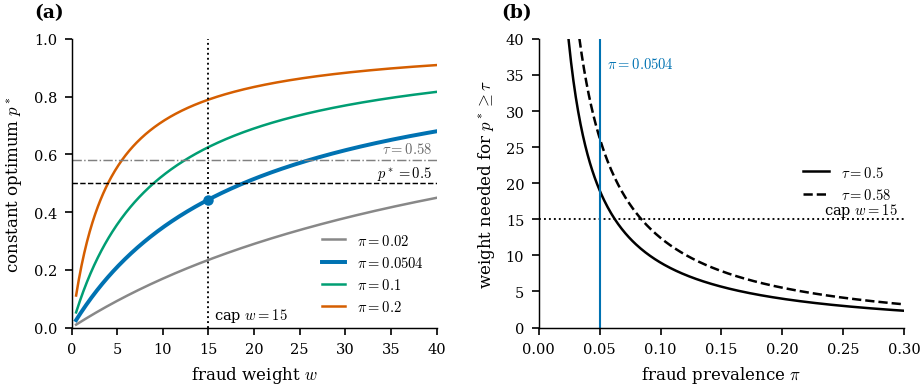

In [10]:
# 1. Lemma 1: constant-score optimum --------------------------------------
w = np.linspace(0.5, 40, 400)
fig, ax = plt.subplots(1, 2, figsize=(W, 2.5), gridspec_kw={"wspace": 0.28})
for pi, col in zip([0.02, 0.0504, 0.10, 0.20], ["#888888", C[0], C[1], C[2]]):
    ax[0].plot(w, w*pi/(w*pi + 1 - pi), color=col, lw=1.9 if pi == 0.0504 else 1.2, label=fr"$\pi={pi:g}$")
ax[0].axvline(15, color="k", ls=":", lw=0.9); ax[0].axhline(0.5, color="k", ls="--", lw=0.7)
ax[0].axhline(0.58, color="grey", ls="-.", lw=0.7)
ax[0].text(39.5, 0.595, r"$\tau=0.58$", ha="right", va="bottom", fontsize=7, color="dimgrey")
ax[0].text(39.5, 0.505, r"$p^*=0.5$", ha="right", va="bottom", fontsize=7)
ax[0].text(15.6, 0.03, r"cap $w=15$", fontsize=7)
ax[0].plot([15], [15*0.0504/(15*0.0504+1-0.0504)], "o", color=C[0], ms=4, zorder=5)
ax[0].set_xlabel(r"fraud weight $w$"); ax[0].set_ylabel(r"constant optimum $p^*$")
ax[0].set_xlim(0, 40); ax[0].set_ylim(0, 1); ax[0].legend(frameon=False, loc="lower right", handlelength=1.6)
panel(ax[0], "(a)")
pis = np.linspace(0.01, 0.30, 300)
for tau, ls in [(0.5, "-"), (0.58, "--")]:
    ax[1].plot(pis, tau*(1-pis)/(pis*(1-tau)), ls=ls, color="k", lw=1.2, label=fr"$\tau={tau}$")
ax[1].axhline(15, color="k", ls=":", lw=0.9); ax[1].text(0.295, 15.8, r"cap $w=15$", ha="right", fontsize=7)
ax[1].axvline(862/17098, color=C[0], lw=1.0); ax[1].text(0.056, 36, r"$\pi=0.0504$", color=C[0], fontsize=7)
ax[1].set_ylim(0, 40); ax[1].set_xlim(0, 0.30)
ax[1].set_xlabel(r"fraud prevalence $\pi$"); ax[1].set_ylabel(r"weight needed for $p^*\geq\tau$")
ax[1].legend(frameon=False, loc="center right", handlelength=1.8); panel(ax[1], "(b)")
save(fig, "fig_lemma1_constant_score")

### Figure 2: Test confusion matrices

Row-normalised test confusion matrices for the three settings, with raw counts in brackets.

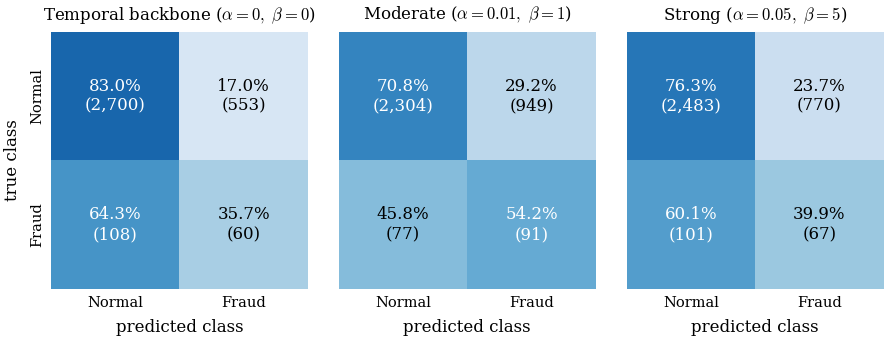

In [11]:
# 2. Confusion matrices ---------------------------------------------------
fig, axs = plt.subplots(1, 3, figsize=(W, 2.35), gridspec_kw={"wspace": 0.12}, sharey=True)
for a, r, n in zip(axs, res, NAMES):
    cm = np.array(r["confusion_matrix"]); rn = cm / cm.sum(1, keepdims=True)
    a.imshow(rn, cmap="Blues", vmin=0, vmax=1.05)
    for i in range(2):
        for j in range(2):
            a.text(j, i, f"{rn[i,j]*100:.1f}%\n({cm[i,j]:,})", ha="center", va="center",
                   fontsize=8, color="white" if rn[i, j] > 0.5 else "black")
    a.set_xticks([0, 1], ["Normal", "Fraud"]); a.set_yticks([0, 1], ["Normal", "Fraud"], rotation=90, va="center")
    a.set_xlabel("predicted class")
    a.set_title(f"{n} " + fr"($\alpha={r['alpha']:g},\ \beta={r['beta']:g}$)", fontsize=8)
    for s in a.spines.values(): s.set_visible(False)
    a.tick_params(length=0)
axs[0].set_ylabel("true class")
save(fig, "fig_confusion_matrices")

### Figure 3: Training histories

(a) Total training objective and (b) logged test ROC-AUC, recorded every 10 epochs.

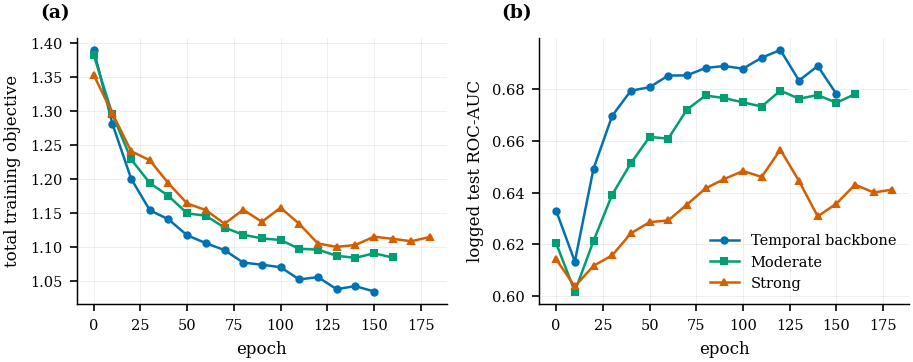

In [12]:
# 3. Logged histories -------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(W, 2.3), gridspec_kw={"wspace": 0.25})
for r, n, c, m in zip(res, NAMES, C, MK):
    h = r["history"]
    ax[0].plot(h["epoch"], h["loss"], color=c, marker=m, ms=3, lw=1.2, label=n)
    ax[1].plot(h["epoch"], h["auc"], color=c, marker=m, ms=3, lw=1.2, label=n)
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("total training objective"); panel(ax[0], "(a)")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("logged test ROC-AUC"); panel(ax[1], "(b)")
ax[1].legend(frameon=False, loc="lower right")
for a in ax: a.grid(alpha=0.25, lw=0.4)
save(fig, "fig_training_histories")

### Figure 4: Accuracy–fairness trade-off and operating points

Test ROC-AUC against (a) the equal-opportunity gap and (b) the statistical-parity gap; (c) each model's operating point (false-positive rate, recall).

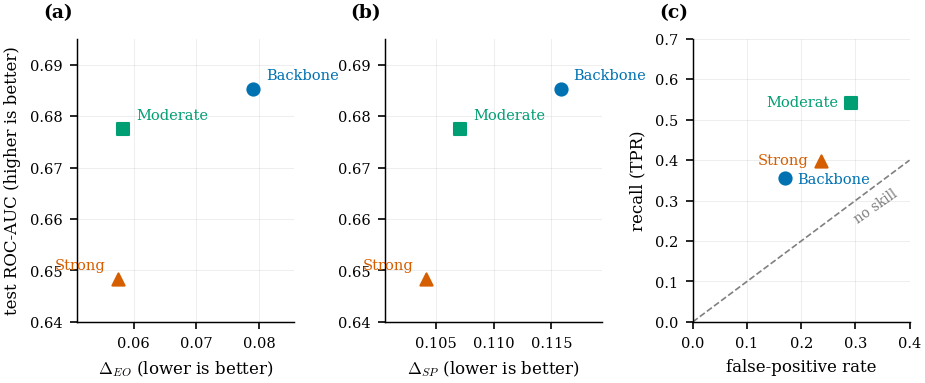

In [13]:
# 4. Trade-off and operating points -------------------------------------------
SH = ["Backbone", "Moderate", "Strong"]
# Direct labels next to each point (no legend box). Offsets in points: (dx, dy, horizontal alignment).
LBL_AB = [(6, 3, "left"), (6, 3, "left"), (-6, 3, "right")]       # Strong labelled on its left
LBL_C = [(6, -1, "left"), (-6, 0, "right"), (-6, 0, "right")]
fig, ax = plt.subplots(1, 3, figsize=(W, 2.45), gridspec_kw={"wspace": 0.42})
for key, a, lab, tag in [("eo", ax[0], r"$\Delta_{EO}$ (lower is better)", "(a)"),
                         ("sp", ax[1], r"$\Delta_{SP}$ (lower is better)", "(b)")]:
    for r, c, m, s, (dx, dy, ha) in zip(res, C, MK, SH, LBL_AB):
        a.scatter(r[key], r["auc"], color=c, marker=m, s=34, zorder=3)
        a.annotate(s, (r[key], r["auc"]), textcoords="offset points", xytext=(dx, dy),
                   ha=ha, va="bottom", fontsize=7, color=c)
    xs = [r[key] for r in res]; pad = (max(xs)-min(xs))*0.30
    a.set_xlim(max(0.0, min(xs)-pad), max(xs)+pad); a.set_ylim(0.640, 0.695)  # gaps are never negative
    a.set_xlabel(lab); a.grid(alpha=0.25, lw=0.4); panel(a, tag)
ax[0].set_ylabel("test ROC-AUC (higher is better)")
for r, c, m, s, (dx, dy, ha) in zip(res, C, MK, SH, LBL_C):
    (tn, fp), (fn, tp) = r["confusion_matrix"]
    x, y = fp/(fp+tn), tp/(tp+fn)
    ax[2].scatter(x, y, color=c, marker=m, s=34, zorder=3)
    ax[2].annotate(s, (x, y), textcoords="offset points", xytext=(dx, dy),
                   ha=ha, va="center", fontsize=7, color=c)
ax[2].plot([0, 0.4], [0, 0.4], color="grey", ls="--", lw=0.8)
ax[2].text(0.33, 0.30, "no skill", rotation=35, ha="center", va="top", fontsize=6.5, color="grey",
           rotation_mode="anchor")
ax[2].set_xlim(0, 0.4); ax[2].set_ylim(0, 0.7); ax[2].set_xlabel("false-positive rate")
ax[2].set_ylabel("recall (TPR)"); ax[2].grid(alpha=0.25, lw=0.4); panel(ax[2], "(c)")
save(fig, "fig_tradeoff_operating")

### Figure 5: Statistics of the evaluated sample

(a) Class balance, (b) relation types and (c) edge timestamps in the sampled subgraph.

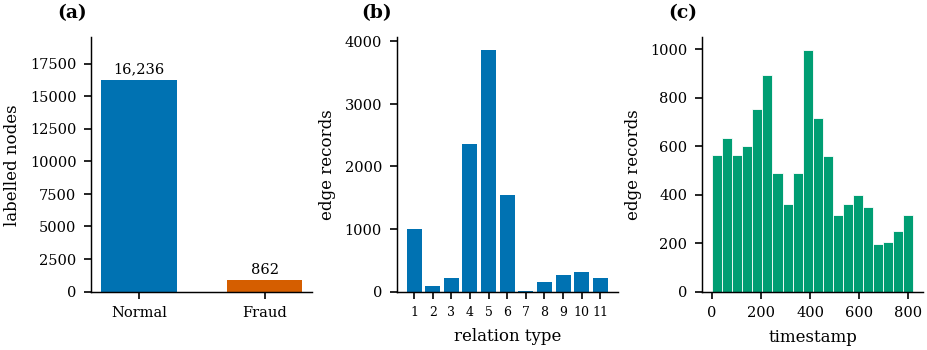

In [14]:
# 5. Statistics of the evaluated sample ---------------------------------------
fig, ax = plt.subplots(1, 3, figsize=(W, 2.2), gridspec_kw={"wspace": 0.38})
vals = [st["n_normal"], st["n_fraud"]]
ax[0].bar(["Normal", "Fraud"], vals, color=[C[0], C[2]], width=0.6)
for i, v in enumerate(vals): ax[0].text(i, v + 300, f"{v:,}", ha="center", va="bottom", fontsize=7)
ax[0].set_ylabel("labelled nodes"); ax[0].set_ylim(0, 19500); panel(ax[0], "(a)")
et = sorted(st["edge_type_dist"].items(), key=lambda kv: int(kv[0]))
ax[1].bar([k for k, _ in et], [v for _, v in et], color=C[0]); ax[1].set_xlabel("relation type")
ax[1].set_ylabel("edge records"); ax[1].tick_params(axis="x", labelsize=6); panel(ax[1], "(b)")
b = st["timestamp_bins"]
ax[2].bar(b[:-1], st["timestamp_dist"], width=np.diff(b), align="edge", color=C[1], edgecolor="white", lw=0.4)
ax[2].set_xlabel("timestamp"); ax[2].set_ylabel("edge records"); panel(ax[2], "(c)")
save(fig, "fig_sample_statistics")

### Figure 6: Full DGraphFin benchmark

Statistics of the complete raw dataset (needs `data/DGraphFin/dgraphfin.npz`).

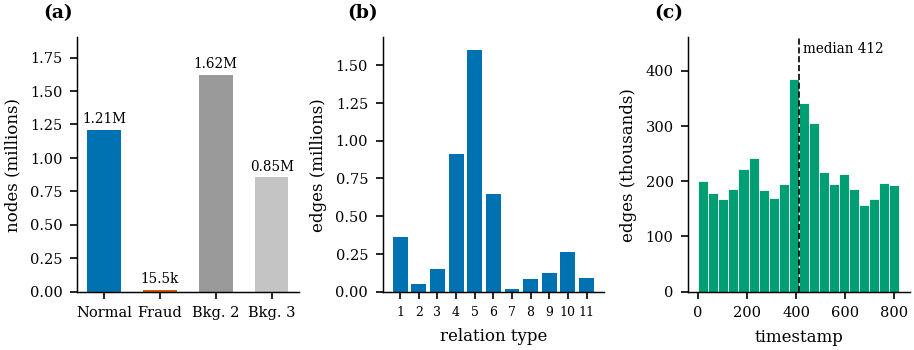

In [15]:
# 6. Full DGraphFin benchmark (raw npz) -------------------------------------------
npz = os.path.join("data", "DGraphFin", "dgraphfin.npz")
if os.path.exists(npz):
    d = np.load(npz)
    y, etype, ets = d["y"], d["edge_type"], d["edge_timestamp"]
    fig, ax = plt.subplots(1, 3, figsize=(W, 2.2), gridspec_kw={"wspace": 0.38})
    cnt = np.bincount(y, minlength=4)
    labs = ["Normal", "Fraud", "Bkg. 2", "Bkg. 3"]
    ax[0].bar(labs, cnt / 1e6, color=[C[0], C[2], "#9a9a9a", "#c4c4c4"], width=0.6)
    for i, v in enumerate(cnt):
        ax[0].text(i, v / 1e6 + 0.03, f"{v/1e6:.2f}M" if v >= 1e5 else f"{v/1e3:.1f}k",
                   ha="center", va="bottom", fontsize=6.5)
    ax[0].set_ylabel("nodes (millions)"); ax[0].set_ylim(0, 1.9)
    ax[0].tick_params(axis="x", labelsize=7); panel(ax[0], "(a)")
    ty, tc = np.unique(etype, return_counts=True)
    ax[1].bar([str(t) for t in ty], tc / 1e6, color=C[0]); ax[1].set_xlabel("relation type")
    ax[1].set_ylabel("edges (millions)"); ax[1].tick_params(axis="x", labelsize=6); panel(ax[1], "(b)")
    med = np.median(ets)
    ax[2].hist(ets, bins=20, color=C[1], edgecolor="white", lw=0.4, weights=np.full(len(ets), 1e-3))
    ax[2].set_ylim(0, 460); ax[2].axvline(med, color="k", ls="--", lw=0.8)
    ax[2].text(med + 18, 452, f"median {med:.0f}", fontsize=6.5, va="top")
    ax[2].set_xlabel("timestamp"); ax[2].set_ylabel("edges (thousands)"); panel(ax[2], "(c)")
    save(fig, "fig_dgraphfin_overview")

### Figure 7: FairGRUNT-T architecture

Fixed temporal adjacency → residual GCN → MLP encoder, split into the task part z_c and the cohort part z_s, each with its own predictor.

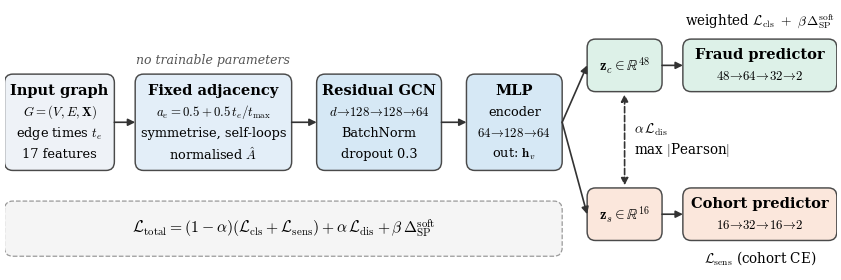

In [16]:
# 7. Architecture diagram -------------------------------------------------------
fig, ax = plt.subplots(figsize=(W, 2.35))
ax.set_xlim(0, 100); ax.set_ylim(0, 31); ax.axis("off")
FILL = {"in": "#eef2f7", "graph": "#e3eef8", "enc": "#d6e8f5", "task": "#ddf1e8", "coh": "#fbe7dc", "loss": "#f5f5f5"}

def box(x, y, w, h, txt, kind, fs=7, bold_first=True, sp=2.4):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0,rounding_size=1.0",
                                fc=FILL[kind], ec="#4a4a4a", lw=0.7))
    lines = txt.split("\n")
    top = y + h/2 + (len(lines)-1)*sp/2
    if bold_first:
        ax.text(x + w/2, top, lines[0], ha="center", va="center", fontsize=fs, fontweight="bold")
        for k, l in enumerate(lines[1:], 1):
            ax.text(x + w/2, top - sp*k, l, ha="center", va="center", fontsize=fs-0.8)
    else:
        ax.text(x + w/2, y + h/2, txt, ha="center", va="center", fontsize=fs)

def arrow(p, q, ls="-", style="-|>"):
    ax.add_patch(FancyArrowPatch(p, q, arrowstyle=style, mutation_scale=7, lw=0.8, color="#333333", ls=ls,
                                 shrinkA=0, shrinkB=0))

YM, H = 12, 11
box(0, YM, 13.2, H, "Input graph\n$G=(V,E,\\mathbf{X})$\nedge times $t_e$\n17 features", "in")
box(15.7, YM, 18.8, H, "Fixed adjacency\n$a_e=0.5+0.5\\,t_e/t_{\\max}$\nsymmetrise, self-loops\nnormalised $\\hat A$", "graph")
box(37.5, YM, 15, H, "Residual GCN\n$d\\!\\to\\!128\\!\\to\\!128\\!\\to\\!64$\nBatchNorm\ndropout 0.3", "enc")
box(55.5, YM, 11.5, H, "MLP\nencoder\n$64\\!\\to\\!128\\!\\to\\!64$\nout: $\\mathbf{h}_v$", "enc")
for a, b in [(13.2, 15.7), (34.5, 37.5), (52.5, 55.5)]:
    arrow((a, YM + H/2), (b, YM + H/2))
ax.text(25.1, YM + H + 1.2, "no trainable parameters", ha="center", fontsize=6, style="italic", color="#555555")
# split
zc_y, zs_y, zh = 21, 4, 6
box(70, zc_y, 9, zh, "$\\mathbf{z}_c\\in\\mathbb{R}^{48}$", "task", bold_first=False)
box(70, zs_y, 9, zh, "$\\mathbf{z}_s\\in\\mathbb{R}^{16}$", "coh", bold_first=False)
arrow((67, YM + H/2), (70, zc_y + zh/2)); arrow((67, YM + H/2), (70, zs_y + zh/2))
box(81.5, zc_y, 18.5, zh, "Fraud predictor\n$48\\!\\to\\!64\\!\\to\\!32\\!\\to\\!2$", "task")
box(81.5, zs_y, 18.5, zh, "Cohort predictor\n$16\\!\\to\\!32\\!\\to\\!16\\!\\to\\!2$", "coh")
arrow((79, zc_y + zh/2), (81.5, zc_y + zh/2)); arrow((79, zs_y + zh/2), (81.5, zs_y + zh/2))
arrow((74.5, zs_y + zh + 0.3), (74.5, zc_y - 0.3), ls="--", style="<|-|>")
ax.text(75.6, (zs_y + zh + zc_y)/2, "$\\alpha\\,\\mathcal{L}_{\\mathrm{dis}}$\nmax $|$Pearson$|$", fontsize=6.5, va="center", ha="left")
ax.text(90.75, zc_y + zh + 1.0, "weighted $\\mathcal{L}_{\\mathrm{cls}}\\ +\\ \\beta\\,\\Delta_{\\mathrm{SP}}^{\\mathrm{soft}}$",
        ha="center", va="bottom", fontsize=6.5)
ax.text(90.75, zs_y - 1.0, "$\\mathcal{L}_{\\mathrm{sens}}$ (cohort CE)", ha="center", va="top", fontsize=6.5)
ax.add_patch(FancyBboxPatch((0, 2.2), 67, 6.3, boxstyle="round,pad=0,rounding_size=1.0", fc=FILL["loss"], ec="#9a9a9a", lw=0.6, ls="--"))
ax.text(33.5, 5.35, "$\\mathcal{L}_{\\mathrm{total}}=(1-\\alpha)(\\mathcal{L}_{\\mathrm{cls}}+\\mathcal{L}_{\\mathrm{sens}})"
        "+\\alpha\\,\\mathcal{L}_{\\mathrm{dis}}+\\beta\\,\\Delta_{\\mathrm{SP}}^{\\mathrm{soft}}$", ha="center", va="center", fontsize=7.5)
save(fig, "fig_architecture")

In [17]:
print("Figures written to", OUT + "/:", ", ".join(sorted(os.listdir(OUT))))

Figures written to figures/: fig_architecture.pdf, fig_architecture.png, fig_confusion_matrices.pdf, fig_confusion_matrices.png, fig_dgraphfin_overview.pdf, fig_dgraphfin_overview.png, fig_lemma1_constant_score.pdf, fig_lemma1_constant_score.png, fig_sample_statistics.pdf, fig_sample_statistics.png, fig_tradeoff_operating.pdf, fig_tradeoff_operating.png, fig_training_histories.pdf, fig_training_histories.png
